# Applying Connectome Spectrum Electromagnetic Tomography (CSET) on individual data

CSET solves the following optimization problem: 
$$\hat {\mathbf s}^* = \text{argmin}_{\mathbf{s}} \lVert \mathbf{LU}\hat{\mathbf s}-\mathbf{y} \rVert_2^2 + \lambda \lVert \hat{\mathbf s}\rVert_1$$
$$ \mathbf s^* = \mathbf U \hat{\mathbf s}$$

where
- $\mathbf{s}^* \in \mathbb{R}^n$ are the reconstructed dipole strengths
- $\hat{\mathbf{s}}^* \in \mathbb{R}^n$ is the reconstructed connectome spectrum.
- $\mathbf{y} \in \mathbb{R}^m$ are the EEG measurements.
- $\mathbf L \in \mathbb{R}^{m\times n}$ is the lead field matrix.
- $\mathbf U \in \mathbb{R}^{n \times n}$ is the inverse graph Fourier transform
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert \hat {\mathbf s}\rVert_1$ imposes the connectome spectrum to be sparse.

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Forward solution (`fwd`): lead field matrix for inversion
- Connectome spectrum transform (`cst`): transform for component base
- EEG (`eeg_inv`): data to inverse
- Ground truth (`gt` - optional): To compare

In [4]:
# configuration
config = mm.io.read_config("../configurations/spike.yml")
sub    = config["SUBS"][3]
sample = config["SAMP"][0]

# data
data = mm.io.read_dataset(sub, "fwd", "cst", "eeg_inv", "gt", sample=sample)
print(f"Loaded: {data.keys()}")
#data["eeg_inv"] = data["eeg_bad"]       # Correct this stuff once finished with it

# features
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                              # forward matrix

sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03}")
print(f"Peak time: {t_peak:03}")

Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Loaded: dict_keys(['fwd', 'cst', 'eeg_inv'])
50% rising phase time: 0.484
Peak time: 0.5


## Ground Truth

### 🌟 Visualize ground truth brain signal

In [139]:
try:
    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)
except KeyError as e:
    print("\033[91mNo ground truth available.\033[0m")

Widget(value='<iframe src="http://localhost:44885/index.html?ui=P_0x79fd573a2c90_135&reconnect=auto" class="py…

In [4]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(data["gt"].data[:,pt]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:45881/index.html?ui=P_0x7d3a0c10eb10_2&reconnect=auto" class="pyvi…

#### 🌟 Visualize ground truth spectrum

In [5]:
mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht])

## EEG

#### 🌟 Visualize EEG time series

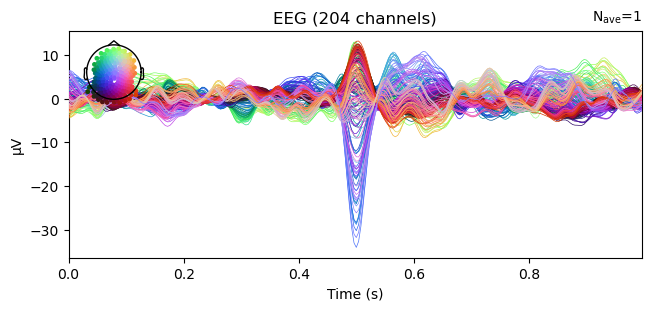

In [5]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

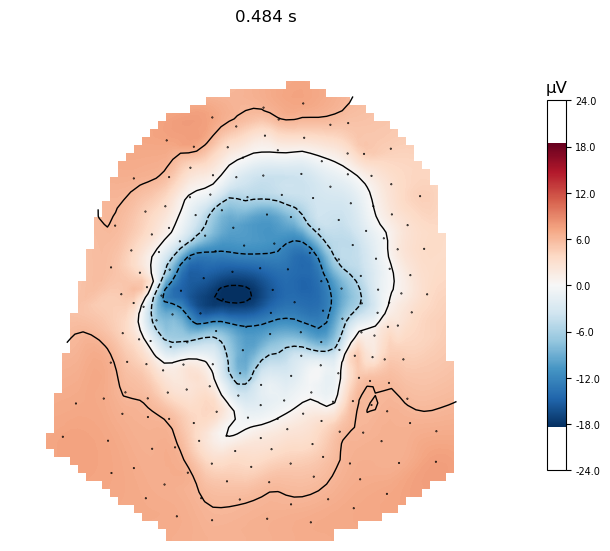

In [7]:
times = [t_half]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

## Select Time points

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct. <br>
🎚️ **<font color=pink>Parameters</font>**
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 30


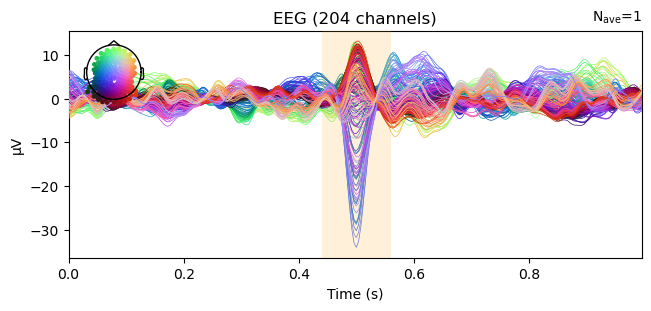

In [8]:
win_size = 0.12      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    b  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    b = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {b.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

## Apply CSET

🛠️ <font color=violet>**Select CSET parameters**</font> 
- $\lambda$ (`lam`): regularizer parameter (influences the connectome spectrum sparsity)

In [12]:
lam = 0.001         # cst sparsness regularizer
dw  = 0             # depth weighting scale
cut_freq = None     # cut off frequency
scale = 1e5         # pyxu does not optimize for small scale so this scales data to big numbers (for optimization) and then descales (for values)

⚙️ <font color=green>**Solve inverse problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [13]:
# ----- Optimization problem -----

# frequency cutoff
if cut_freq is not None:
    cst = data["cst"][:cut_freq,:]
else:
    cst = data["cst"]

# standardize
bnorms   = np.linalg.norm(b, axis=0)
bn       = b/bnorms[None,:]

A      = fwd - np.mean(fwd, axis=0)
Anorms = np.linalg.norm(A, axis=0)**dw
A      = A / Anorms[None,:] 

# component-wise transformation
A = A @ cst.T

# prior sparsity
prior = lam*pxo.L1Norm(dim_shape=cst.shape[0])

# initial guess
alpha0 = np.random.random(A.shape[1])*10**(-9)

# pyxu components
A     = pxa.LinOp.from_array(A)
prior = lam*pxo.L1Norm(dim_shape=cst.shape[0])
recon = np.zeros((cst.shape[1], b.shape[1]))
sc    = pxst.MaxIter(3000)


# ----- Optimization solving -----
for t in range(b.shape[1]):
    bt    = bn[:,t]*scale     # data time point

    likelihood = pxo.SquaredL2Norm(dim_shape=A.codim_shape).argshift(-bt)*A
    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=prior, show_progress=False)

    solver.fit(x0=alpha0, stop_crit=sc)

    alpha = solver.solution().squeeze()
    recon[:,t] = (1/Anorms) * (cst.T @ alpha) * bnorms[t] / scale

#### <font color=yellow>🌟</font> Visualize reconstruction

In [14]:
viz = np.abs(recon) / (np.max(np.abs(recon), axis=0)+1e-15)
mm.viz.plot_brain_time_series(data["fwd"]["src"], viz, t_start=t_start, sfreq=sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:33151/index.html?ui=P_0x7a56f4767110_2&reconnect=auto" class="pyvi…

In [169]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(recon[:,idx_half]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:44885/index.html?ui=P_0x79fd573a2120_172&reconnect=auto" class="py…

In [208]:
mm.viz.plot_spectrum(data["cst"]@recon[:,idx_peak])

#### 💾 **Save result**

In [ ]:
fname  = f"{sub}_{sample}_cset-{lam}"
folder = Path(config["MM_DIR"])/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving source time course of {sub}, {sample}")
vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc = mne.SourceEstimate(recon, vertices, tmin=t_start, tstep=1/sfreq, subject=sub)
stc.save(folder/fname, overwrite=True, verbose="warning")

Saving source time course of sub-pat18, 


# Applying CSET on dataset

## 📦 Imports

In [11]:
import mindmap as mm
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Configuration file (`config`)
- `subjects`: list of subjects to process
- `samples`: list of samples to process


🎚️ **<font color=pink>Parameters</font>**
- Regularizer parameter (`lam`)
- Time window size (`win_size`)
- Depth Weighting scale (`dw`)
- Scale (`scale`)

In [15]:
# config
config   = mm.io.read_config("../configurations/simf.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])
fname    = lambda sub, samp, lam: mm_dir/sub/"inv"/f"{sub}_{samp}_cset-{lam}"

# parameters
win_size = 0.1 
lam      = 0.1 
dw       = 1
scale    = 1

In [16]:
for sub in config["SUBS"]:
    for samp in config["SAMP"]:
        try: 
            data = mm.io.read_dataset(sub, "eeg_inv", "fwd", "cst", sample=samp)
            stc  = mm.cset(data["eeg_inv"], data["fwd"], data["cst"], lam, dw, win_size, scale, sub)
        except Exception as e:
            print(f"\033[91mSkipped {sub}, {samp} due to {e}\033[0m")
            continue

        file = fname(sub, samp, lam)
        if not file.parent.exists():
            file.parent.mkdir()

        stc.save(fname(sub, samp, lam), overwrite=True, verbose="warning")
        print(f"\033[92m{sub}, {samp} successfully reconstructed\033[0m")

vepcon_sub-10, sample1 successfully reconstructed
vepcon_sub-10, sample2 successfully reconstructed
vepcon_sub-10, sample3 successfully reconstructed
vepcon_sub-10, sample4 successfully reconstructed
vepcon_sub-10, sample5 successfully reconstructed
vepcon_sub-10, sample6 successfully reconstructed
vepcon_sub-10, sample7 successfully reconstructed
vepcon_sub-10, sample8 successfully reconstructed
vepcon_sub-10, sample9 successfully reconstructed
vepcon_sub-10, sample10 successfully reconstructed
vepcon_sub-10, sample11 successfully reconstructed
vepcon_sub-10, sample12 successfully reconstructed
vepcon_sub-10, sample13 successfully reconstructed
vepcon_sub-10, sample14 successfully reconstructed
vepcon_sub-10, sample15 successfully reconstructed
vepcon_sub-10, sample16 successfully reconstructed
vepcon_sub-10, sample17 successfully reconstructed
vepcon_sub-10, sample18 successfully reconstructed
vepcon_sub-10, sample19 successfully reconstructed
vepcon_sub-10, sample20 successfully rec